In [97]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [98]:
df = pd.read_csv('House_Rent.csv', usecols=['Size', 'Rent'])

In [99]:
df.head()

,Rent,Size
0,10000,1100
1,20000,800
2,17000,1000
3,10000,800
4,7500,850


In [100]:
df.shape

(4746, 2)

## Using Sklearn

Text(0, 0.5, 'RENT')

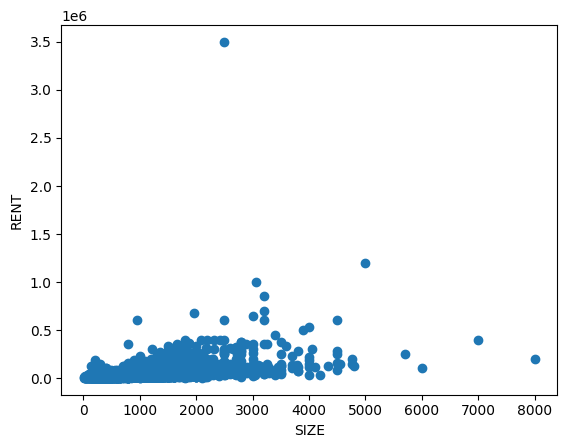

In [101]:
#Scatter Plot

plt.scatter(df['Size'], df['Rent'])
plt.xlabel('SIZE')
plt.ylabel('RENT')

In [102]:
x = df[['Size']]
y = df['Rent']




In [103]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [104]:
from sklearn.linear_model import LinearRegression 

In [105]:
lr = LinearRegression()

In [106]:
lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [107]:
x_test

,Size
1566,1100
3159,800
538,518
2630,1500
4418,2235
...,...
4124,1248
3400,1100
1941,950
3679,1125


In [108]:
y_test

1566    16000
3159    12000
538     28000
2630     8000
4418    46000
        ...  
4124    18000
3400    25000
1941    14000
3679    26000
2531    11000
Name: Rent, Length: 950, dtype: int64

In [109]:
lr.predict(x_test.iloc[[0]])

array([41724.4933439])

Text(0, 0.5, 'RENT')

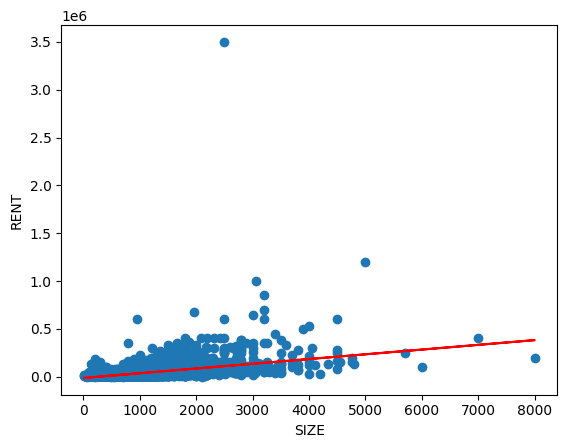

In [110]:
plt.scatter(df['Size'], df['Rent'])
plt.plot(x_train, lr.predict(x_train), color = 'red')
plt.xlabel('SIZE')
plt.ylabel('RENT')

In [111]:
# y = mx + b 

m = lr.coef_

In [112]:
b = lr.intercept_
b

np.float64(-12677.589503208852)

In [113]:
m * 1100 + b

array([41724.4933439])

## Apply regression Metrics

In [114]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [115]:
y_test.values

array([  16000,   12000,   28000,    8000,   46000,   17000,   57000,
          9500,  400000,   15000,   10000,   12000,   27000,   16000,
         15000,    8500,  140000,   12000,    6000,   60000,   38000,
          7500,   23000,   14000,  260000,    5000,    6000,   16500,
          6500,   15000,    5000,   14000,    5000,   12000,   25000,
         25000,    7500,    6000,   17000,    7000,   13000,  320000,
         14000,    6000,   60000,   14000,   32000,   65000,  350000,
         15000,   11000,   35000,   18000,   12000,   65000,  130000,
         35000,   40000,    9000,    9000,   18000,    5000,  130000,
         12000,   50000,   20000,   18000,   15500,   34999,   30000,
         13000,   24000,  100000,    7000,   25000,   35000,   12000,
         61500,   35000,   28000,   14000,   10000,   33500,   10000,
         12000,   45000,   36000,   18000,   25000,   27000,  260000,
         35000,   24000,  120000,   13000,   12000,   11000,    7000,
         20000,   24

In [116]:
y_pred = lr.predict(x_test)

In [117]:
print('MAE', mean_absolute_error(y_test, y_pred))

MAE 27779.361957965782


In [118]:
print('MSE', mean_squared_error(y_test, y_pred))

MSE 2720800316.247958


In [119]:
print('RMSE', np.sqrt(mean_squared_error(y_test, y_pred)))

RMSE 52161.29135909078


In [120]:
print('r2_score', r2_score(y_test, y_pred))

r2_score 0.3173048951366573


In [121]:
x_test.shape

(950, 1)

In [122]:
# Adjusted r2_score

r2 = r2_score(y_test, y_pred)

1 - ((1-r2)*(950-1)/(950-1-1))

0.31658475262097874

## Creat LR Model from Scratch

In [124]:
class myLR:

    def __init__(self): 
        self.m = None
        self.b = None

    def fit(self, x_train, y_train):
        num = 0 
        den = 0
        for i in range(x_train.shape[0]):

            num = num + ((x_train[i])-(x_train.mean()) * (y_train[i])-(y_train.mean()))
            den = ((x_train[i])-(x_train.mean()) * (x_train[i])-(x_train.mean()))
        
        self.m = num/den
        self.b = (y_train.mean()) - (self.m * x_train.mean())

        print(self.m)
        print(self.b)


        

    def predict(self, x_test):
        print(x_test)

        return self.m * x_test + self.b

In [125]:
lr = myLR()

In [126]:
lr.fit(x_train, y_train)


KeyError: 0